<a href="https://colab.research.google.com/github/ntanphu/ML-HK261/blob/main/experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chương 4 — Thực nghiệm và kết quả

Chương này triển khai Diffusion Maps trên Swiss Roll và MNIST, phân tích độ nhạy theo băng thông $\varepsilon$, đồng thời so sánh với PCA và t-SNE. Các phương pháp sử dụng cùng dữ liệu đầu vào, cùng số chiều đích và cùng tiêu chí đánh giá. Toàn bộ bước lấy mẫu và các thuật toán ngẫu nhiên sử dụng \`SEED = 42\` để bảo đảm khả năng tái lập.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from IPython.display import display, Markdown
from scipy.linalg import eigh
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.datasets import make_swiss_roll
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from tensorflow.keras.datasets import mnist

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

OUTPUT_DIR = '/content/pictures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

matplotlib.rcParams.update({'font.family': 'serif', 'font.size': 8.2, 'axes.titlesize': 8.8, 'axes.labelsize': 8.2, 'xtick.labelsize': 7.0, 'ytick.labelsize': 7.0, 'legend.fontsize': 7.0, 'figure.dpi': 140, 'savefig.dpi': 600, 'axes.linewidth': 0.7, 'axes.spines.top': False, 'axes.spines.right': False, 'xtick.direction': 'out', 'ytick.direction': 'out', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'text.usetex': False})

CB = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442', 'blue': '#0072B2', 'vermilion': '#D55E00', 'pink': '#CC79A7', 'black': '#000000'}
METHOD_COLORS = {'Diffusion Maps': CB['blue'], 'PCA': CB['vermilion'], 't-SNE': CB['green']}

print('Môi trường thực nghiệm đã sẵn sàng.')


Môi trường thực nghiệm đã sẵn sàng.


## 4.1. Tổng quan thực nghiệm và bộ dữ liệu

Thực nghiệm sử dụng Swiss Roll để kiểm tra khả năng khôi phục hình học đa tạp và MNIST để đánh giá dữ liệu ảnh nhiều chiều.

### Bộ dữ liệu 1 — Swiss Roll ($n=600$)

Swiss Roll là đa tạp hai chiều được nhúng trong $\mathbb{R}^3$ theo $(t\cos t,h,t\sin t)$. Bộ dữ liệu gồm 600 mẫu, nhiễu Gaussian $\sigma=0.3$ và \`random_state = 42\`. Ba tọa độ quan sát được chuẩn hóa bằng z-score trước khi áp dụng các phương pháp giảm chiều.

### Bộ dữ liệu 2 — MNIST ($n=600$)

MNIST gồm các ảnh chữ số viết tay mức xám $28\times28$, được biểu diễn bằng vectơ 784 chiều. Tập con cân bằng gồm 60 ảnh cho mỗi chữ số, tổng cộng 600 ảnh, được lấy mẫu với \`SEED = 42\`. Giá trị điểm ảnh được chuẩn hóa từ $[0,255]$ về $[0,1]$. Nhãn lớp chỉ được dùng để trực quan hóa và đánh giá.

Trên từng bộ dữ liệu, Diffusion Maps, PCA và t-SNE sử dụng cùng ma trận đầu vào và cùng số chiều đích $m=2$.


In [3]:
N_SR = 600
N_PER_DIGIT = 60
N_MNIST = 10 * N_PER_DIGIT

X_sr_raw, t_sr = make_swiss_roll(n_samples=N_SR, noise=0.3, random_state=SEED)
X_sr = StandardScaler().fit_transform(X_sr_raw)
h_sr = X_sr_raw[:, 1]
s_sr = 0.5 * (t_sr * np.sqrt(1.0 + t_sr ** 2) + np.arcsinh(t_sr))
X_sr_reference = np.column_stack([s_sr, h_sr])

(X_mnist_train, y_mnist_train), (_, _) = mnist.load_data()
mnist_indices = np.concatenate([rng.choice(np.where(y_mnist_train == digit)[0], size=N_PER_DIGIT, replace=False) for digit in range(10)])
rng.shuffle(mnist_indices)
X_mnist_images = X_mnist_train[mnist_indices]
y_mnist = y_mnist_train[mnist_indices]
X_mnist = X_mnist_images.reshape(N_MNIST, 784).astype(np.float64) / 255.0

print('Swiss Roll : n={}, d={}, t in [{:.3f}, {:.3f}]'.format(N_SR, X_sr.shape[1], t_sr.min(), t_sr.max()))
print('MNIST      : n={}, d={}, class counts={}'.format(N_MNIST, X_mnist.shape[1], np.bincount(y_mnist, minlength=10).tolist()))


Swiss Roll : n=600, d=3, t in [4.760, 14.135]
MNIST      : n=600, d=784, class counts=[60, 60, 60, 60, 60, 60, 60, 60, 60, 60]


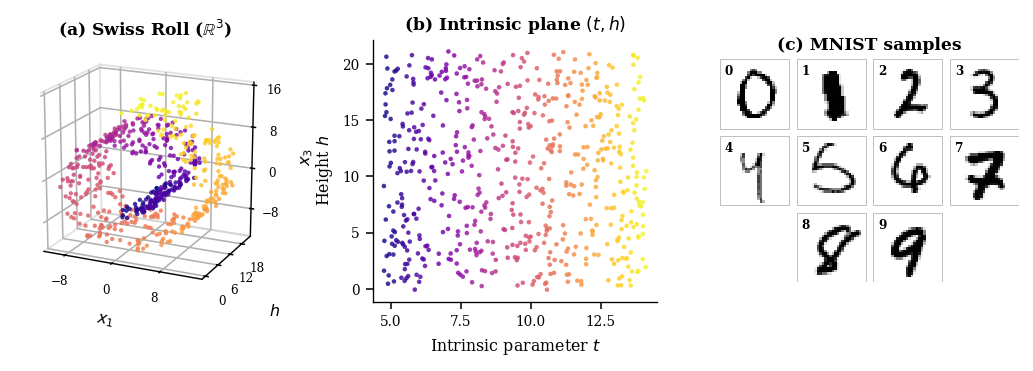

Saved: /content/pictures/fig_datasets.pdf


In [4]:
# ── Hình tổng quan dữ liệu ──────────────────────────────────────────────────
mnist_examples = [X_mnist_images[np.where(y_mnist == digit)[0][0]] for digit in range(10)]
digit_positions = [(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3), (2, 1), (2, 2)]
tile_size = 28
tile_gap = 3
mnist_canvas = np.zeros((3 * tile_size + 2 * tile_gap, 4 * tile_size + 3 * tile_gap))

for digit, (row, column) in enumerate(digit_positions):
    y_start = row * (tile_size + tile_gap)
    x_start = column * (tile_size + tile_gap)
    mnist_canvas[y_start:y_start + tile_size, x_start:x_start + tile_size] = mnist_examples[digit]

t_color_norm = mcolors.Normalize(vmin=t_sr.min(), vmax=t_sr.max())
fig = plt.figure(figsize=(7.5, 2.60))
fig.set_layout_engine('none')
ax1 = fig.add_axes([0.010, 0.16, 0.285, 0.72], projection='3d')
ax2 = fig.add_axes([0.370, 0.16, 0.270, 0.72])
ax3 = fig.add_axes([0.700, 0.16, 0.285, 0.72])

sc1 = ax1.scatter(X_sr_raw[:, 0], X_sr_raw[:, 1], X_sr_raw[:, 2], c=t_sr, cmap='plasma', norm=t_color_norm, s=5.0, alpha=0.82, linewidths=0, depthshade=False, rasterized=True)

for pane in [ax1.xaxis.pane, ax1.yaxis.pane, ax1.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor('0.78')

ax1.grid(True, linewidth=0.25, alpha=0.28)
ax1.set_xlabel('$x_1$', labelpad=-2)
ax1.set_ylabel('$h$', labelpad=0)
ax1.set_zlabel('$x_3$', labelpad=-2)
ax1.tick_params(labelsize=6.2, pad=-1)
ax1.xaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.yaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.zaxis.set_major_locator(ticker.MaxNLocator(4))
ax1.set_box_aspect((1.05, 0.78, 1.00))
ax1.view_init(elev=18, azim=-65)
ax1.set_title('(a) Swiss Roll ($\\mathbb{R}^3$)', fontweight='bold', pad=1)

ax2.scatter(t_sr, h_sr, c=t_sr, cmap='plasma', norm=t_color_norm, s=5.5, alpha=0.82, linewidths=0, rasterized=True)
ax2.set_xlabel('Intrinsic parameter $t$')
ax2.set_ylabel('Height $h$')
ax2.xaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.yaxis.set_major_locator(ticker.MaxNLocator(5))
ax2.set_title('(b) Intrinsic plane $(t,h)$', fontweight='bold', pad=5)
ax2.margins(x=0.04, y=0.05)

ax3.imshow(mnist_canvas, cmap='gray_r', vmin=0, vmax=255, interpolation='nearest', rasterized=True)

for digit, (row, column) in enumerate(digit_positions):
    y_start = row * (tile_size + tile_gap)
    x_start = column * (tile_size + tile_gap)
    border = mpatches.Rectangle((x_start - 0.5, y_start - 0.5), tile_size, tile_size, fill=False, edgecolor='0.72', linewidth=0.45)
    ax3.add_patch(border)
    ax3.text(x_start + 1.5, y_start + 4.5, str(digit), fontsize=6.2, fontweight='bold', color='black', ha='left', va='center', bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78, 'pad': 0.25})

ax3.set_title('(c) MNIST samples', fontweight='bold', pad=5)
ax3.set_axis_off()

overview_path = os.path.join(OUTPUT_DIR, 'fig_datasets.pdf')
fig.savefig(overview_path, dpi=600, bbox_inches='tight', pad_inches=0.04, facecolor='white')
plt.show()
print('Saved:', overview_path)


## 4.2. Xây dựng Diffusion Maps và lựa chọn tham số

Với dữ liệu $X=\{x_i\}_{i=1}^{n}$, Diffusion Maps được triển khai như sau:

1. Kernel Gaussian: $W_{ij}=\exp(-\lVert x_i-x_j\rVert^2/\varepsilon)$.
2. Chuẩn hóa mật độ: $\widetilde W_{ij}=W_{ij}/(q_i^\alpha q_j^\alpha)$, với $q_i=\sum_jW_{ij}$.
3. Ma trận Markov: $P=D^{-1}\widetilde W$.
4. Phân rã phổ và biểu diễn: $\Phi_t(x_i)=(\lambda_1^t\psi_1(i),\lambda_2^t\psi_2(i))$.

Thiết lập thực nghiệm sử dụng $\alpha=1$, thời gian khuếch tán $t=1$ và số chiều đầu ra $m=2$. Băng thông tham chiếu được xác định bằng quy tắc trung vị

$$\varepsilon^*=\operatorname{median}_{i<j}\lVert x_i-x_j\rVert^2.$$

Độ nhạy theo băng thông được khảo sát tại $\{0.25,0.5,1,2,4\}\varepsilon^*$. Các so sánh chính sử dụng $\varepsilon=\varepsilon^*$; nhãn MNIST không tham gia lựa chọn tham số hoặc xây dựng biểu diễn.


In [5]:
def median_bandwidth(X):
    upper = np.triu_indices(len(X), k=1)
    return float(np.median(cdist(X, X, metric='sqeuclidean')[upper]))

def build_diffusion_map(X, epsilon, alpha=1.0, n_components=6, diffusion_time=1, embedding_dim=2):
    if epsilon <= 0:
        raise ValueError('epsilon must be positive.')
    D2 = cdist(X, X, metric='sqeuclidean')
    W = np.exp(-D2 / epsilon)
    q = np.maximum(W.sum(axis=1), np.finfo(float).eps)
    W_tilde = W / np.outer(q ** alpha, q ** alpha)
    d = np.maximum(W_tilde.sum(axis=1), np.finfo(float).eps)
    P = W_tilde / d[:, None]
    d_sqrt = np.sqrt(d)
    S = W_tilde / np.outer(d_sqrt, d_sqrt)
    S = 0.5 * (S + S.T)
    n = X.shape[0]
    k = min(n_components + 1, n)
    eigenvalues, eigenvectors = eigh(S, subset_by_index=[n - k, n - 1])
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]
    right_eigenvectors = eigenvectors / d_sqrt[:, None]
    right_eigenvectors = right_eigenvectors / right_eigenvectors[:, [0]]
    nontrivial_values = eigenvalues[1:]
    nontrivial_vectors = right_eigenvectors[:, 1:]
    coordinates = nontrivial_vectors[:, :embedding_dim] * (nontrivial_values[:embedding_dim] ** diffusion_time)
    return {'embedding': coordinates, 'eigenvalues': nontrivial_values, 'eigenvectors': nontrivial_vectors, 'P': P, 'W': W, 'W_tilde': W_tilde, 'epsilon': epsilon, 'alpha': alpha, 'diffusion_time': diffusion_time}

EPS_FACTORS = np.array([0.25, 0.50, 1.00, 2.00, 4.00])
ALPHA = 1.0
DIFFUSION_TIME = 1
EMBEDDING_DIM = 2

eps_sr_star = median_bandwidth(X_sr)
eps_mnist_star = median_bandwidth(X_mnist)

print('Swiss Roll : epsilon* = {:.6f}'.format(eps_sr_star))
print('MNIST      : epsilon* = {:.6f}'.format(eps_mnist_star))


Swiss Roll : epsilon* = 5.379471
MNIST      : epsilon* = 103.753856


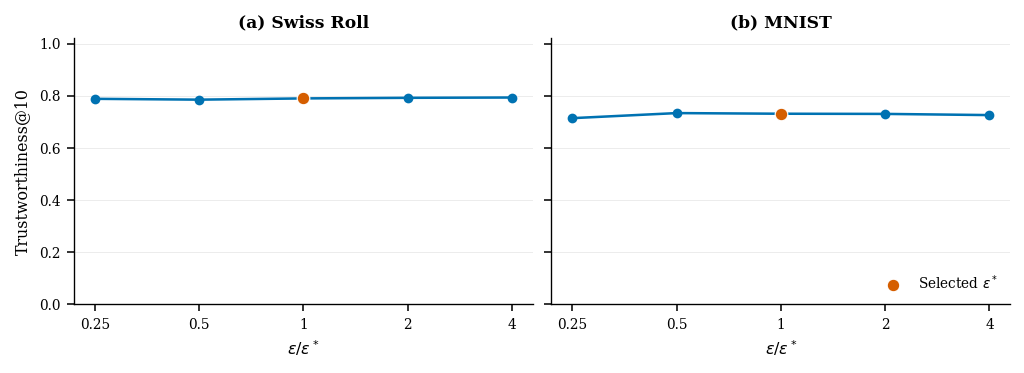

Saved: /content/pictures/fig4_2_epsilon_sensitivity.pdf


In [6]:
def diffusion_sensitivity(X, X_reference, epsilon_star, factors, n_neighbors=10):
    records = []
    for factor in factors:
        result = build_diffusion_map(X, epsilon=factor * epsilon_star, alpha=ALPHA, n_components=6, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM)
        score = trustworthiness(X_reference, result['embedding'], n_neighbors=n_neighbors)
        records.append({'factor': factor, 'epsilon': factor * epsilon_star, 'trustworthiness': score})
    return pd.DataFrame(records)

sensitivity_sr = diffusion_sensitivity(X_sr, X_sr_reference, eps_sr_star, EPS_FACTORS)
sensitivity_mnist = diffusion_sensitivity(X_mnist, X_mnist, eps_mnist_star, EPS_FACTORS)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.55), sharey=True, constrained_layout=True)

for ax, data, title in zip(axes, [sensitivity_sr, sensitivity_mnist], ['(a) Swiss Roll', '(b) MNIST']):
    ax.plot(data['factor'], data['trustworthiness'], marker='o', color=CB['blue'], linewidth=1.3, markersize=4)
    selected = data[np.isclose(data['factor'], 1.0)].iloc[0]
    ax.scatter([selected['factor']], [selected['trustworthiness']], s=42, color=CB['vermilion'], edgecolor='white', linewidth=0.6, zorder=4, label='Selected $\\varepsilon^*$')
    ax.set_xscale('log', base=2)
    ax.set_xticks(EPS_FACTORS)
    ax.set_xticklabels(['0.25', '0.5', '1', '2', '4'])
    ax.set_xlabel('$\\varepsilon/\\varepsilon^*$')
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0.0, 1.02)
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

axes[0].set_ylabel('Trustworthiness@10')
axes[1].legend(frameon=False, loc='lower right')
sensitivity_path = os.path.join(OUTPUT_DIR, 'fig4_2_epsilon_sensitivity.pdf')
fig.savefig(sensitivity_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', sensitivity_path)


## 4.3. So sánh biểu diễn hai chiều

Thiết lập của ba phương pháp được cố định như sau:

- **Diffusion Maps:** $\varepsilon=\varepsilon^*$, $\alpha=1$, $t=1$, $m=2$.
- **PCA:** hai thành phần chính đầu tiên.
- **t-SNE:** \`perplexity = 30\`, \`init = 'pca'\`, \`learning_rate = 'auto'\` và \`random_state = 42\`.

Trong các hình kết quả, màu của Swiss Roll biểu diễn tham số nội tại $t$; màu của MNIST biểu diễn nhãn chữ số.


In [7]:
dm_sr_result = build_diffusion_map(X_sr, epsilon=eps_sr_star, alpha=ALPHA, n_components=6, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM)
dm_mnist_result = build_diffusion_map(X_mnist, epsilon=eps_mnist_star, alpha=ALPHA, n_components=6, diffusion_time=DIFFUSION_TIME, embedding_dim=EMBEDDING_DIM)

dm_sr = dm_sr_result['embedding']
dm_mnist = dm_mnist_result['embedding']
pca_sr = PCA(n_components=2, random_state=SEED).fit_transform(X_sr)
pca_mnist = PCA(n_components=2, random_state=SEED).fit_transform(X_mnist)

def run_tsne(X):
    try:
        model = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', max_iter=1000, random_state=SEED)
    except TypeError:
        model = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', n_iter=1000, random_state=SEED)
    return model.fit_transform(X)

tsne_sr = run_tsne(X_sr)
tsne_mnist = run_tsne(X_mnist)

EMBEDDINGS_SR = {'Diffusion Maps': dm_sr, 'PCA': pca_sr, 't-SNE': tsne_sr}
EMBEDDINGS_MNIST = {'Diffusion Maps': dm_mnist, 'PCA': pca_mnist, 't-SNE': tsne_mnist}

print('Đã tính xong sáu biểu diễn hai chiều.')


Đã tính xong sáu biểu diễn hai chiều.


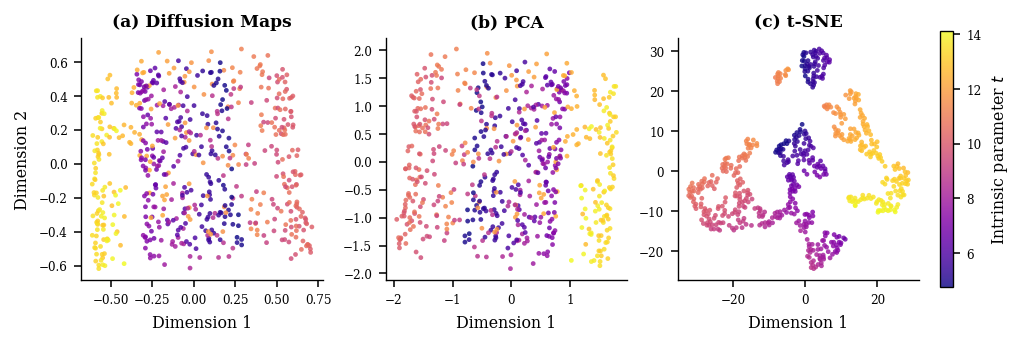

Saved: /content/pictures/swiss_roll_embeddings.pdf


In [8]:
# ── Swiss Roll embeddings ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45), constrained_layout=True)

for panel, (ax, (method, embedding)) in enumerate(zip(axes, EMBEDDINGS_SR.items())):
    sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=t_sr, cmap='plasma', s=6.0, alpha=0.82, linewidths=0, rasterized=True)
    ax.set_title('({}) {}'.format(chr(97 + panel), method), fontweight='bold')
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2' if panel == 0 else '')
    ax.tick_params(labelsize=6.2)
    ax.set_box_aspect(1)

colorbar = fig.colorbar(sc, ax=axes.ravel().tolist(), fraction=0.030, pad=0.025, shrink=0.82)
colorbar.set_label('Intrinsic parameter $t$')
colorbar.ax.tick_params(labelsize=6.2)
swiss_embedding_path = os.path.join(OUTPUT_DIR, 'swiss_roll_embeddings.pdf')
fig.savefig(swiss_embedding_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', swiss_embedding_path)


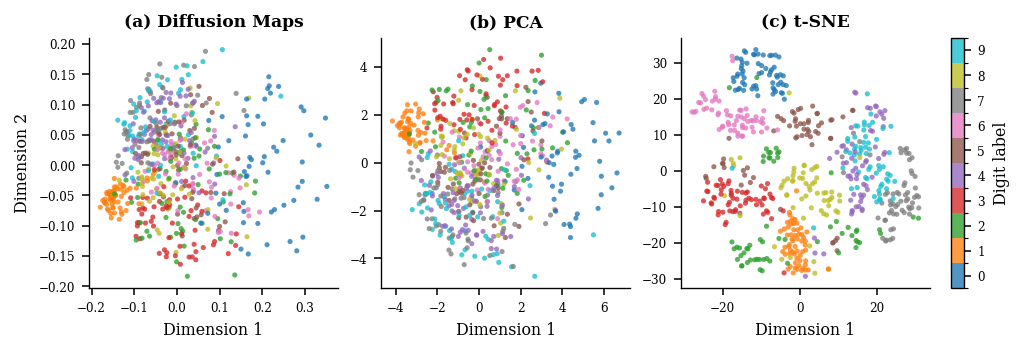

Saved: /content/pictures/mnist_embeddings.pdf


In [9]:
# ── MNIST embeddings ────────────────────────────────────────────────────────
digit_cmap = plt.get_cmap('tab10', 10)
digit_norm = mcolors.BoundaryNorm(np.arange(-0.5, 10.5, 1.0), digit_cmap.N)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45), constrained_layout=True)

for panel, (ax, (method, embedding)) in enumerate(zip(axes, EMBEDDINGS_MNIST.items())):
    sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=y_mnist, cmap=digit_cmap, norm=digit_norm, s=7.0, alpha=0.78, linewidths=0, rasterized=True)
    ax.set_title('({}) {}'.format(chr(97 + panel), method), fontweight='bold')
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2' if panel == 0 else '')
    ax.tick_params(labelsize=6.2)
    ax.set_box_aspect(1)

colorbar = fig.colorbar(sc, ax=axes.ravel().tolist(), ticks=np.arange(10), fraction=0.030, pad=0.025, shrink=0.82)
colorbar.set_label('Digit label')
colorbar.ax.tick_params(labelsize=6.2)
mnist_embedding_path = os.path.join(OUTPUT_DIR, 'mnist_embeddings.pdf')
fig.savefig(mnist_embedding_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', mnist_embedding_path)


## 4.4. Tiêu chí và phương pháp đánh giá

Ba tiêu chí hình học được áp dụng cho Diffusion Maps, PCA và t-SNE trên cả hai bộ dữ liệu: tỷ lệ bảo toàn lân cận, trustworthiness và tương quan thứ hạng khoảng cách. Độ chính xác 5-NN được bổ sung cho MNIST để đánh giá mức độ phân tách lớp trong không gian hai chiều.

Không gian tham chiếu của Swiss Roll là $Z_{\mathrm{SR}}=(s(t),h)$, với

$$s(t)=\frac{1}{2}\left[t\sqrt{1+t^2}+\operatorname{asinh}(t)\right].$$

Tọa độ $s(t)$ là độ dài cung theo hướng cuộn; do đó khoảng cách trong $(s(t),h)$ phản ánh hình học nội tại của Swiss Roll tốt hơn khoảng cách Euclid trong không gian nhúng $\mathbb{R}^3$. Không gian tham chiếu của MNIST là không gian điểm ảnh 784 chiều đã chuẩn hóa về $[0,1]$.

### 4.4.1. Tỷ lệ bảo toàn lân cận

Với mỗi điểm $i$, gọi $\mathcal{N}_k^X(i)$ và $\mathcal{N}_k^Y(i)$ là tập $k$ láng giềng gần nhất trong không gian tham chiếu và trong biểu diễn hai chiều. Tỷ lệ lân cận được bảo toàn là

$$\operatorname{Overlap}_k=\frac{1}{n}\sum_{i=1}^{n}\frac{|\mathcal{N}_k^X(i)\cap\mathcal{N}_k^Y(i)|}{k}.\tag{4.1}$$

Chỉ số thuộc $[0,1]$; giá trị lớn biểu thị mức bảo toàn lân cận cao. Phép đo được thực hiện với $k=1,\ldots,20$. Công thức (4.1) không phải hệ số Jaccard vì mẫu số là $k$, không phải kích thước hợp của hai tập lân cận.

### 4.4.2. Trustworthiness

Trustworthiness định lượng mức độ các điểm không thuộc lân cận trong không gian tham chiếu lại xuất hiện trong lân cận của biểu diễn hai chiều. Chỉ số được tính tại $k=10$ và nhận giá trị trong $[0,1]$; giá trị lớn biểu thị ít quan hệ lân cận sai lệch hơn.

### 4.4.3. Tương quan thứ hạng khoảng cách

Gọi $d_X$ và $d_Y$ là các vectơ khoảng cách cặp trong không gian tham chiếu và trong biểu diễn hai chiều. Phép đo sử dụng cùng một tập con 300 điểm được lấy với \`SEED = 42\`, tạo ra $\binom{300}{2}=44\,850$ cặp khoảng cách. Hệ số Spearman được xác định bởi

$$\rho(d_X,d_Y)=\operatorname{corr}(\operatorname{rank}(d_X),\operatorname{rank}(d_Y)).\tag{4.2}$$

$\rho=1$ biểu thị thứ hạng khoảng cách được bảo toàn hoàn toàn, không đồng nghĩa với bảo toàn giá trị khoảng cách hay phép nhúng đẳng cự. Chỉ số vẫn được tính cho t-SNE để đối chiếu, nhưng không được dùng làm tiêu chí duy nhất vì hàm mục tiêu của t-SNE không tối ưu khoảng cách toàn cục.

### 4.4.4. Độ chính xác 5-NN trên MNIST

Độ chính xác của bộ phân loại 5-NN được tính trên từng biểu diễn MNIST bằng kiểm định chéo phân tầng 5-fold. Nhãn lớp chỉ được sử dụng trong phép đánh giá này.


In [10]:
def knn_overlap_curve(X_reference, X_embedding, ks):
    max_k = int(np.max(ks))
    original_neighbors = NearestNeighbors(n_neighbors=max_k + 1, algorithm='auto', n_jobs=-1).fit(X_reference).kneighbors(X_reference, return_distance=False)[:, 1:]
    embedded_neighbors = NearestNeighbors(n_neighbors=max_k + 1, algorithm='auto', n_jobs=-1).fit(X_embedding).kneighbors(X_embedding, return_distance=False)[:, 1:]
    scores = []
    for k in ks:
        score = np.mean([len(set(original_neighbors[i, :k]) & set(embedded_neighbors[i, :k])) / k for i in range(len(X_reference))])
        scores.append(score)
    return np.asarray(scores)

def distance_rank_correlation(X_reference, X_embedding, n_sub=300, seed=SEED):
    local_rng = np.random.default_rng(seed)
    n_use = min(n_sub, len(X_reference))
    indices = local_rng.choice(len(X_reference), size=n_use, replace=False)
    upper = np.triu_indices(n_use, k=1)
    distance_reference = cdist(X_reference[indices], X_reference[indices], metric='euclidean')[upper]
    distance_embedding = cdist(X_embedding[indices], X_embedding[indices], metric='euclidean')[upper]
    return float(spearmanr(distance_reference, distance_embedding).statistic)

def embedding_knn_accuracy(X_embedding, labels, seed=SEED):
    model = KNeighborsClassifier(n_neighbors=5)
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    return float(cross_val_score(model, X_embedding, labels, cv=folds, scoring='accuracy').mean())

KS = np.arange(1, 21)
OVERLAP_CURVES = {'Swiss Roll': {}, 'MNIST': {}}
RESULT_ROWS = []

for dataset_name, X_reference, embeddings, labels in [('Swiss Roll', X_sr_reference, EMBEDDINGS_SR, None), ('MNIST', X_mnist, EMBEDDINGS_MNIST, y_mnist)]:
    for method, embedding in embeddings.items():
        curve = knn_overlap_curve(X_reference, embedding, KS)
        OVERLAP_CURVES[dataset_name][method] = curve
        trust = float(trustworthiness(X_reference, embedding, n_neighbors=10))
        rho = distance_rank_correlation(X_reference, embedding, n_sub=300, seed=SEED)
        accuracy = np.nan if labels is None else embedding_knn_accuracy(embedding, labels, seed=SEED)
        RESULT_ROWS.append({'Dataset': dataset_name, 'Method': method, 'Mean kNN overlap': float(curve.mean()), 'Trustworthiness@10': trust, 'Spearman rho': rho, '5-NN accuracy': accuracy})

results_df = pd.DataFrame(RESULT_ROWS)
display(results_df.round(4))


,Dataset,Method,Mean kNN overlap,Trustworthiness@10,Spearman rho,5-NN accuracy
0,Swiss Roll,Diffusion Maps,0.4246,0.7893,0.3333,NaN
1,Swiss Roll,PCA,0.4218,0.7940,0.3411,NaN
2,Swiss Roll,t-SNE,0.8341,0.9990,0.4175,NaN
3,MNIST,Diffusion Maps,0.1492,0.7304,0.5489,0.3683
4,MNIST,PCA,0.1474,0.7249,0.5004,0.3833
5,MNIST,t-SNE,0.5433,0.9521,0.4152,0.8450


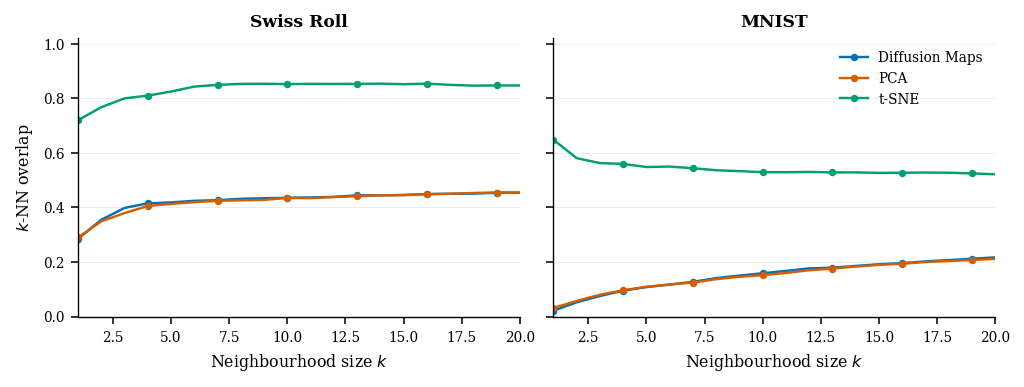

Saved: /content/pictures/knn_overlap.pdf


In [12]:
# ── k-NN overlap curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.65), sharey=True, constrained_layout=True)

for ax, dataset_name in zip(axes, ['Swiss Roll', 'MNIST']):
    for method in ['Diffusion Maps', 'PCA', 't-SNE']:
        ax.plot(KS, OVERLAP_CURVES[dataset_name][method], color=METHOD_COLORS[method], linewidth=1.25, marker='o', markersize=2.8, markevery=3, label=method)
    ax.set_xlabel('Neighbourhood size $k$')
    ax.set_title(dataset_name, fontweight='bold')
    ax.set_xlim(1, 20)
    ax.set_ylim(0, 1.02)
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

axes[0].set_ylabel('$k$-NN overlap')
axes[1].legend(frameon=False, loc='best')
overlap_path = os.path.join(OUTPUT_DIR, 'knn_overlap.pdf')
fig.savefig(overlap_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', overlap_path)


## 4.5. Phân tích và so sánh kết quả

Phương pháp có giá trị lớn nhất được xem là tốt hơn đối với đúng thuộc tính mà chỉ số đang đo. Tỷ lệ bảo toàn lân cận và trustworthiness được dùng để so sánh cấu trúc cục bộ; Spearman $\rho$ được dùng để so sánh thứ hạng khoảng cách; độ chính xác 5-NN được dùng để so sánh khả năng phân tách chữ số trên MNIST. Chênh lệch giữa phương pháp đứng đầu và đứng thứ hai được báo cáo để tránh kết luận chỉ từ thứ hạng.

Đối với Swiss Roll, ba tiêu chí hình học được ưu tiên vì cấu trúc nội tại đã biết. Đối với MNIST, các tiêu chí lân cận được xem xét cùng độ chính xác 5-NN. Không gộp các chỉ số thành một điểm tổng hợp vì mỗi chỉ số biểu diễn một mục tiêu khác nhau. Các kết luận dưới đây chỉ có giá trị trong thiết lập dữ liệu và tham số của thực nghiệm này.


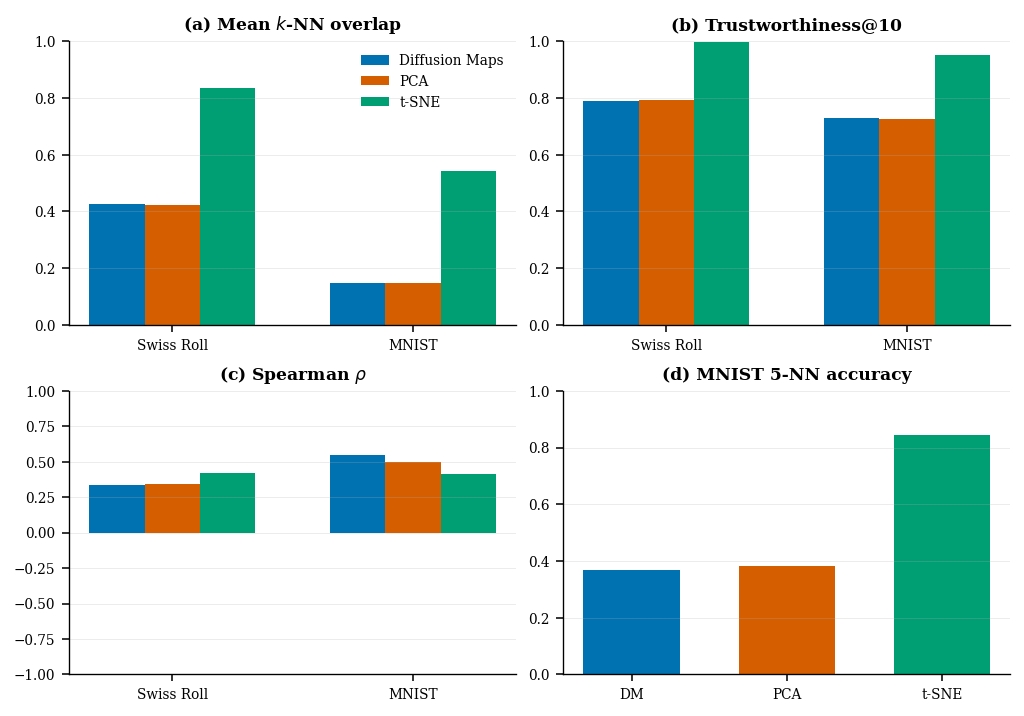

Saved: /content/pictures/quantitative_summary.pdf
Saved: /content/pictures/table4_quantitative_results.csv


,Dataset,Method,Mean kNN overlap,Trustworthiness@10,Spearman rho,5-NN accuracy
0,Swiss Roll,Diffusion Maps,0.4246,0.7893,0.3333,NaN
1,Swiss Roll,PCA,0.4218,0.7940,0.3411,NaN
2,Swiss Roll,t-SNE,0.8341,0.9990,0.4175,NaN
3,MNIST,Diffusion Maps,0.1492,0.7304,0.5489,0.3683
4,MNIST,PCA,0.1474,0.7249,0.5004,0.3833
5,MNIST,t-SNE,0.5433,0.9521,0.4152,0.8450


In [13]:
def grouped_metric_bars(ax, dataframe, metric, title, ylim=(0.0, 1.0)):
    datasets = ['Swiss Roll', 'MNIST']
    methods = ['Diffusion Maps', 'PCA', 't-SNE']
    x = np.arange(len(datasets))
    width = 0.23
    for index, method in enumerate(methods):
        values = [float(dataframe[(dataframe['Dataset'] == dataset) & (dataframe['Method'] == method)][metric].iloc[0]) for dataset in datasets]
        ax.bar(x + (index - 1) * width, values, width=width, color=METHOD_COLORS[method], label=method)
    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.set_ylim(*ylim)
    ax.set_title(title, fontweight='bold')
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), constrained_layout=True)
grouped_metric_bars(axes[0, 0], results_df, 'Mean kNN overlap', '(a) Mean $k$-NN overlap')
grouped_metric_bars(axes[0, 1], results_df, 'Trustworthiness@10', '(b) Trustworthiness@10')
grouped_metric_bars(axes[1, 0], results_df, 'Spearman rho', '(c) Spearman $\\rho$', ylim=(-1.0, 1.0))
axes[0, 0].legend(frameon=False, loc='upper right')

mnist_rows = results_df[results_df['Dataset'] == 'MNIST'].set_index('Method').loc[['Diffusion Maps', 'PCA', 't-SNE']]
axes[1, 1].bar(np.arange(3), mnist_rows['5-NN accuracy'].values, color=[METHOD_COLORS[method] for method in mnist_rows.index], width=0.62)
axes[1, 1].set_xticks(np.arange(3))
axes[1, 1].set_xticklabels(['DM', 'PCA', 't-SNE'])
axes[1, 1].set_ylim(0.0, 1.0)
axes[1, 1].set_title('(d) MNIST 5-NN accuracy', fontweight='bold')
axes[1, 1].grid(axis='y', linewidth=0.35, alpha=0.35)

summary_path = os.path.join(OUTPUT_DIR, 'quantitative_summary.pdf')
fig.savefig(summary_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()

results_path = os.path.join(OUTPUT_DIR, 'table4_quantitative_results.csv')
results_df.to_csv(results_path, index=False)
print('Saved:', summary_path)
print('Saved:', results_path)
display(results_df.round(4))


In [ ]:
METRIC_MEANINGS = {'Mean kNN overlap': 'bảo toàn tập lân cận', 'Trustworthiness@10': 'độ tin cậy của quan hệ lân cận', 'Spearman rho': 'bảo toàn thứ hạng khoảng cách', '5-NN accuracy': 'phân tách lớp MNIST'}
comparison_rows = []

for dataset_name in ['Swiss Roll', 'MNIST']:
    dataset_results = results_df[results_df['Dataset'] == dataset_name]
    metrics = ['Mean kNN overlap', 'Trustworthiness@10', 'Spearman rho']
    if dataset_name == 'MNIST':
        metrics.append('5-NN accuracy')
    for metric in metrics:
        ranking = dataset_results[['Method', metric]].dropna().sort_values(metric, ascending=False).reset_index(drop=True)
        comparison_rows.append({'Dataset': dataset_name, 'Criterion': METRIC_MEANINGS[metric], 'Best method': ranking.loc[0, 'Method'], 'Best score': ranking.loc[0, metric], 'Runner-up': ranking.loc[1, 'Method'], 'Margin': ranking.loc[0, metric] - ranking.loc[1, metric]})

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

for dataset_name in ['Swiss Roll', 'MNIST']:
    subset = comparison_df[comparison_df['Dataset'] == dataset_name]
    winner_counts = subset['Best method'].value_counts()
    leading_method = winner_counts.index[0]
    leading_count = int(winner_counts.iloc[0])
    details = ['{}: {} ({:.4f}; hơn phương pháp kế tiếp {:.4f})'.format(row['Criterion'], row['Best method'], row['Best score'], row['Margin']) for _, row in subset.iterrows()]
    if leading_count == len(subset):
        conclusion = '{} đứng đầu toàn bộ {} tiêu chí của {} trong lần chạy này.'.format(leading_method, len(subset), dataset_name)
    else:
        conclusion = 'Không có phương pháp chi phối toàn bộ tiêu chí của {}. {} đứng đầu {}/{} tiêu chí; kết quả thể hiện sự đánh đổi giữa các mục tiêu.'.format(dataset_name, leading_method, leading_count, len(subset))
    display(Markdown('### Kết luận trên {}\n\n{}\n\n- {}'.format(dataset_name, conclusion, '\n- '.join(details))))


,Dataset,Criterion,Best method,Best score,Runner-up,Margin
0,Swiss Roll,bảo toàn tập lân cận,t-SNE,0.8341,Diffusion Maps,0.4095
1,Swiss Roll,độ tin cậy của quan hệ lân cận,t-SNE,0.9990,PCA,0.2050
2,Swiss Roll,bảo toàn thứ hạng khoảng cách,t-SNE,0.4175,PCA,0.0764
3,MNIST,bảo toàn tập lân cận,t-SNE,0.5423,Diffusion Maps,0.3821
4,MNIST,độ tin cậy của quan hệ lân cận,t-SNE,0.9450,Diffusion Maps,0.2111
5,MNIST,bảo toàn thứ hạng khoảng cách,Diffusion Maps,0.5427,PCA,0.0330
6,MNIST,phân tách lớp MNIST,t-SNE,0.8133,PCA,0.4200


### Kết luận trên Swiss Roll

t-SNE đứng đầu toàn bộ 3 tiêu chí của Swiss Roll trong lần chạy này.

- bảo toàn tập lân cận: t-SNE (0.8341; hơn phương pháp kế tiếp 0.4095)
- độ tin cậy của quan hệ lân cận: t-SNE (0.9990; hơn phương pháp kế tiếp 0.2050)
- bảo toàn thứ hạng khoảng cách: t-SNE (0.4175; hơn phương pháp kế tiếp 0.0764)

### Kết luận trên MNIST

Không có phương pháp chi phối toàn bộ tiêu chí của MNIST. t-SNE đứng đầu 3/4 tiêu chí; kết quả thể hiện sự đánh đổi giữa các mục tiêu.

- bảo toàn tập lân cận: t-SNE (0.5423; hơn phương pháp kế tiếp 0.3821)
- độ tin cậy của quan hệ lân cận: t-SNE (0.9450; hơn phương pháp kế tiếp 0.2111)
- bảo toàn thứ hạng khoảng cách: Diffusion Maps (0.5427; hơn phương pháp kế tiếp 0.0330)
- phân tách lớp MNIST: t-SNE (0.8133; hơn phương pháp kế tiếp 0.4200)

## 4.6. Vấn đề được giải quyết và giới hạn còn lại

### Vấn đề được giải quyết

- **Biểu diễn cấu trúc phi tuyến:** Diffusion Maps thay phép chiếu tuyến tính bằng các tọa độ phổ của quá trình khuếch tán. Cách tiếp cận này mô hình hóa quan hệ giữa các điểm thông qua nhiều bước chuyển tiếp trên đồ thị tương đồng, phù hợp với mục tiêu bảo toàn cấu trúc nội tại của Swiss Roll.
- **Đánh giá trên nhiều thuộc tính:** quy trình thực nghiệm tách riêng bảo toàn lân cận, thứ hạng khoảng cách và khả năng phân tách lớp. Vì vậy, nhận định phương pháp tốt hơn được gắn với một tiêu chí cụ thể thay vì chỉ dựa vào hình chiếu hai chiều.
- **Kiểm tra độ nhạy tham số:** ảnh hưởng của $\varepsilon$ được khảo sát quanh $\varepsilon^*$, qua đó xác định mức độ phụ thuộc của Diffusion Maps vào băng thông kernel.
- **So sánh có cùng điều kiện:** Diffusion Maps, PCA và t-SNE sử dụng cùng mẫu dữ liệu, cùng số chiều đầu ra và cùng seed. Lợi thế của từng phương pháp được xác định từ bảng xếp hạng ở Mục 4.5.

### Ý nghĩa lựa chọn phương pháp

- Diffusion Maps được ưu tiên khi mục tiêu là bảo toàn hình học phi tuyến và quan hệ chuyển tiếp trên đa tạp; kết luận này cần được đối chiếu với các chỉ số hình học của từng bộ dữ liệu.
- t-SNE được ưu tiên cho trực quan hóa lân cận hoặc phân tách cụm khi các chỉ số cục bộ và 5-NN cao hơn; khoảng cách giữa các cụm không được diễn giải như khoảng cách toàn cục.
- PCA phù hợp khi dữ liệu gần tuyến tính hoặc khi cần mô hình đơn giản, tính toán nhanh và phép biến đổi trực tiếp cho mẫu mới.

### Vấn đề chưa được giải quyết

- Quy tắc trung vị chỉ cung cấp giá trị khởi tạo cho $\varepsilon$; notebook chưa xây dựng thủ tục lựa chọn đồng thời $\varepsilon$, $\alpha$ và $t$ theo một tiêu chí độc lập.
- Kernel dày cần $O(n^2)$ bộ nhớ và phân rã phổ trở nên tốn kém khi $n$ lớn. Triển khai chưa sử dụng đồ thị thưa hoặc bộ giải trị riêng xấp xỉ.
- Notebook chưa triển khai phép mở rộng ngoài mẫu cho Diffusion Maps và t-SNE; vì vậy chưa đánh giá khả năng ánh xạ dữ liệu mới.
- Kết quả được tính với một lần lấy mẫu và một seed, chưa có khoảng tin cậy qua nhiều lần lặp.
- MNIST chỉ sử dụng tập con cân bằng 600 ảnh. Kết quả chưa đại diện cho toàn bộ MNIST hoặc các bộ dữ liệu thực tế khác.
- Diffusion Maps là phương pháp không giám sát nên không bảo đảm phân tách lớp. Độ chính xác 5-NN chỉ đo thông tin lớp còn lại trong biểu diễn, không phải mục tiêu tối ưu trực tiếp của thuật toán.

Trong phạm vi này, thực nghiệm xác định điều kiện mà mỗi phương pháp có lợi thế nhưng chưa chứng minh một phương pháp luôn vượt trội trên mọi mục tiêu và mọi bộ dữ liệu.
